# Day 2: Supervised learning on housing affordability

**Group 8** · IAAC MaAI 2026–27 · AI Methods · Day 2

Builds on the Day 1 output `data/housing_affordability_model_ready.csv` (1,210 rows × 29 columns, one row = one country in one year, 1977–2024).

**Task:** predict **next year's affordability** (`affordability_next`) for a country, from what is known this year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# works whether the notebook is run from the repo root or from notebook/
csv_name = "housing_affordability_model_ready.csv"
data_dir = Path("data") if (Path("data") / csv_name).exists() else Path("../data")
df = pd.read_csv(data_dir / csv_name)
print(df.shape)
df.head()

(1210, 29)


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
0,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
1,38.880944,AUS,1978,1970,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,...,0,0,0,0,0,0,0,1,0,0
2,42.938456,AUS,1979,1970,38.880944,21.75,55.94,2.208647,0.053658,38.061170,...,0,0,0,0,0,0,0,1,0,0
3,44.351318,AUS,1980,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,...,0,0,0,0,0,0,0,1,0,0
4,41.449879,AUS,1981,1980,44.351318,25.40,57.27,5.219553,1.867663,42.938456,...,0,0,0,0,0,0,0,1,0,0


# 1. Core concepts

## 1.1 Train / test split

A model evaluated on the data it learned from looks great, because it may simply have **memorised** the answers. We can only measure learning on rows it has **not seen**. So before anything else we **split** the data:

- **Training set** (~80%): the model learns from it.
- **Test set** (~20%): locked away and used **once, at the very end**, to estimate performance on new data.

**Why we do not shuffle.** `train_test_split` shuffles rows randomly. For our data that would be a form of leakage (see README §8.2): neighbouring years of the same country are almost identical, so training on 2014 and 2016 and testing on 2015 lets the model "see the future". Our real use case is forecasting, so we split **by time**:

- **Train:** 1977–2014
- **Test:** 2015–2024 (10 years × 26 countries = 260 rows, ≈ 21%)

The cut is on a year boundary, so all 26 countries of a given year are always on the same side. **We keep this split for the whole notebook.**

### Target: log10 of next year's affordability

`affordability_next` is strongly right-skewed: most values are around 100, but South Korea in the late 1970s–early 1980s reaches above 550 (skewness ≈ 5.4). On a log scale the distribution is much closer to a bell curve (skewness ≈ 0.9), so we predict **`log10(affordability_next)`**. A prediction is turned back into an affordability value with `10 ** y_pred`.

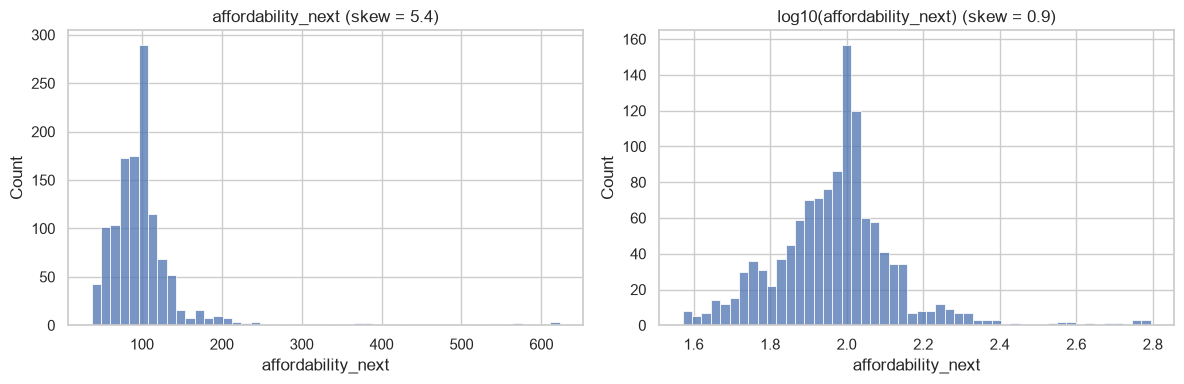

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["affordability_next"], bins=50, ax=axes[0])
axes[0].set_title(f"affordability_next (skew = {df['affordability_next'].skew():.1f})")
sns.histplot(np.log10(df["affordability_next"]), bins=50, ax=axes[1])
axes[1].set_title(f"log10(affordability_next) (skew = {np.log10(df['affordability_next']).skew():.1f})")
plt.tight_layout()
plt.show()

### Inputs: remove what must not be used

We drop from the inputs:
- `affordability_next`: the **target** itself (using it as an input would be the ultimate leak).
- `iso`: a country **identifier**, not a measurement (text, and it would let the model memorise countries).
- `data_reliable`, `is_latest_year`: **constant** in the model-ready file (always 1 and 0 after Day 1 filtering), so they carry no information.

The two leaking features from Day 1 (`affordability_vs_own_avg`, `affordability_position`) were already removed from this file. More on leakage in 1.5.

In [3]:
TARGET = "affordability_next"
drop_cols = [TARGET, "iso", "data_reliable", "is_latest_year"]

X = df.drop(columns=drop_cols)
y = np.log10(df[TARGET])

# time-based split: train up to 2014, test from 2015
SPLIT_YEAR = 2015
is_train = df["year"] < SPLIT_YEAR

X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print(f"Features: {X.shape[1]}")
print(f"Train: {len(X_train)} rows ({len(X_train) / len(X):.0%}), years {df.loc[is_train, 'year'].min()}–{df.loc[is_train, 'year'].max()}")
print(f"Test:  {len(X_test)} rows ({len(X_test) / len(X):.0%}), years {df.loc[~is_train, 'year'].min()}–{df.loc[~is_train, 'year'].max()}")

Features: 25
Train: 950 rows (79%), years 1977–2014
Test:  260 rows (21%), years 2015–2024


In [4]:
# sanity checks: no overlap in time, every country in both sets
assert df.loc[is_train, "year"].max() < df.loc[~is_train, "year"].min()
assert set(df.loc[is_train, "iso"]) == set(df.loc[~is_train, "iso"])
X.columns.tolist()

['year',
 'decade',
 'affordability',
 'real_house_price_index',
 'real_personal_disposable_income',
 'real_hpi_change_pct',
 'real_income_change_pct',
 'affordability_lag1',
 'affordability_lag2',
 'affordability_3yr_avg',
 'nominal_zero',
 'hyperinflation_country',
 'price_shock_up',
 'price_shock_down',
 'gfc_period',
 'region_Africa',
 'region_Asia',
 'region_Central/Eastern Europe',
 'region_Latin America',
 'region_Middle East',
 'region_Nordic',
 'region_North America',
 'region_Oceania',
 'region_Southern Europe',
 'region_Western Europe']

## 1.2 Underfitting and overfitting

A model can fail in two opposite ways:

| | **Underfitting** | **Good fit** | **Overfitting** |
|---|---|---|---|
| What happens | The model is too **simple** to capture the pattern | Captures the pattern, ignores the noise | The model is too **complex**: it memorises the noise |
| Training error | High | Low | **Very low** |
| Test error | High | Low | **High** |
| Analogy | A student who only learned "the answer is usually C" | A student who understood the subject | A student who memorised last year's exam |

### Synthetic example: window-to-wall ratio vs energy demand

We invent a "true" relation between the **window-to-wall ratio** (WWR) of a façade and its **energy demand**: too few windows means more artificial lighting, too many means more heat loss and overheating, so the curve is U-shaped with an optimum around 35%. We add random noise (like measurement errors), then fit three polynomial curves of increasing complexity on the training points (dark) and check them on the test points (orange).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

rng = np.random.default_rng(42)

def true_demand(wwr):
    # kWh/m²/year: minimum around 35% WWR
    return 90 + 400 * (wwr - 0.35) ** 2

wwr = rng.uniform(0.05, 0.90, 40)
demand = true_demand(wwr) + rng.normal(0, 8, wwr.size)

# synthetic data has no time order, so a random split is fine here
wwr_train, wwr_test, dem_train, dem_test = train_test_split(
    wwr, demand, test_size=0.3, random_state=42)
print(len(wwr_train), "train points,", len(wwr_test), "test points")

28 train points, 12 test points


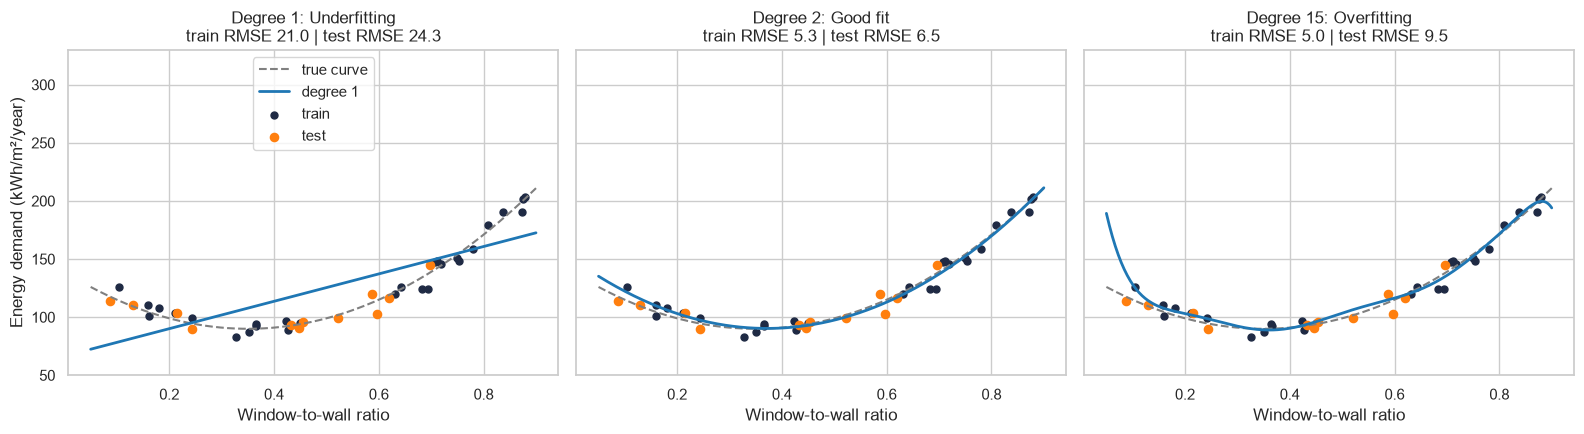

,degree,fit,train RMSE,test RMSE
0,1,Underfitting,21.0,24.3
1,2,Good fit,5.3,6.5
2,15,Overfitting,5.0,9.5


In [6]:
degrees = {1: "Underfitting", 2: "Good fit", 15: "Overfitting"}
grid = np.linspace(0.05, 0.90, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
rows = []
for ax, (deg, label) in zip(axes, degrees.items()):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)

    rmse_train = root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1)))
    rmse_test = root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1)))
    rows.append({"degree": deg, "fit": label, "train RMSE": rmse_train, "test RMSE": rmse_test})

    ax.plot(grid, true_demand(grid), "--", color="grey", label="true curve")
    ax.plot(grid, model.predict(grid.reshape(-1, 1)), color="tab:blue", linewidth=2, label=f"degree {deg}")
    ax.scatter(wwr_train, dem_train, color="#1f2a44", s=25, label="train")
    ax.scatter(wwr_test, dem_test, color="tab:orange", s=35, label="test")
    ax.set_ylim(50, 330)
    ax.set_title(f"Degree {deg}: {label}\ntrain RMSE {rmse_train:.1f} | test RMSE {rmse_test:.1f}")
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand (kWh/m²/year)")
axes[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(1)

### Error vs complexity

Training error keeps falling as the polynomial degree grows: a more flexible curve can always pass closer to the training points. Test error falls at first, then **rises again** once the model starts fitting the noise. The best model sits at the bottom of the test curve, not the training curve.

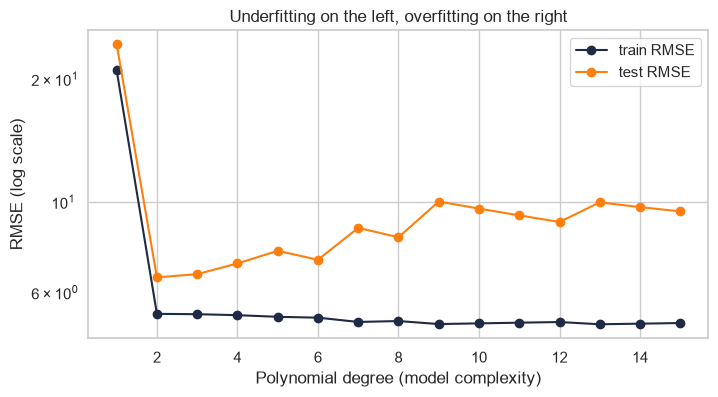

In [7]:
sweep = []
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)
    sweep.append({
        "degree": deg,
        "train": root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1))),
        "test": root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1))),
    })
sweep = pd.DataFrame(sweep)

plt.figure(figsize=(8, 4))
plt.plot(sweep["degree"], sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(sweep["degree"], sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.yscale("log")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE (log scale)")
plt.title("Underfitting on the left, overfitting on the right")
plt.legend()
plt.show()

### The same check on our housing data

We apply the idea to the real task using a **decision tree**, whose complexity is set by `max_depth` (how many yes/no questions it can ask in a row). We use the time-based split from 1.1. Errors are RMSE on `log10(affordability_next)`.

This is only a diagnostic: picking the depth by looking at the test set would leak it into model selection. Later we choose hyperparameters with validation data instead.

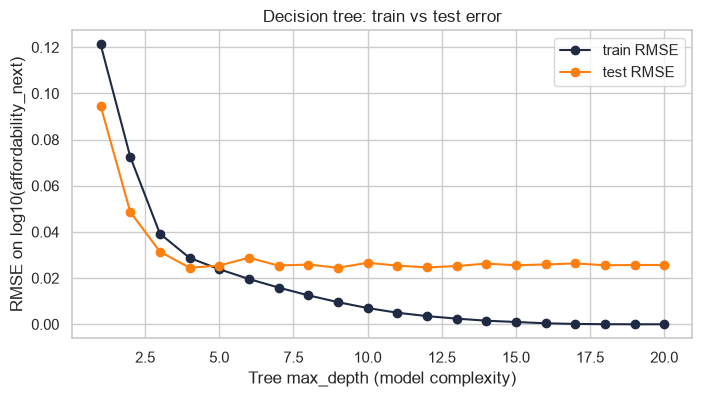

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.1213,0.0726,0.0393,0.0287,0.0238,0.0196,0.0159,0.0126,0.0096,0.0070,0.0050,0.0035,0.0024,0.0015,0.0010,0.0004,0.0001,0.0000,0.0000,0.0000
test,0.0947,0.0487,0.0315,0.0245,0.0254,0.0288,0.0254,0.0259,0.0245,0.0266,0.0254,0.0246,0.0252,0.0263,0.0256,0.0259,0.0264,0.0256,0.0257,0.0257


In [8]:
from sklearn.tree import DecisionTreeRegressor

tree_sweep = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    tree_sweep.append({
        "max_depth": depth,
        "train": root_mean_squared_error(y_train, tree.predict(X_train)),
        "test": root_mean_squared_error(y_test, tree.predict(X_test)),
    })
tree_sweep = pd.DataFrame(tree_sweep)

plt.figure(figsize=(8, 4))
plt.plot(tree_sweep["max_depth"], tree_sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(tree_sweep["max_depth"], tree_sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("RMSE on log10(affordability_next)")
plt.title("Decision tree: train vs test error")
plt.legend()
plt.show()

tree_sweep.round(4).set_index("max_depth").T

### What we see

**Synthetic example**
- **Degree 1 (underfitting):** a straight line cannot follow the U-shape. Train and test errors are both high (≈ 21 and 24 kWh/m²/year).
- **Degree 2 (good fit):** follows the true curve. Train and test errors are both low and close (≈ 5 and 6.5).
- **Degree 15 (overfitting):** the lowest training error, but the test error almost doubles (≈ 9.5) and the curve shoots up at the left edge where there are few training points.

**Housing data (decision tree)**
- **Depth 1–3, underfitting:** both errors are high. Test error is even *below* training error here, because the training years include the extreme early values (e.g. South Korea 1978–83) that the test years 2015–2024 do not have.
- **Depth ≈ 4–5, good fit:** test error reaches its minimum, about 0.025 in log10, which is roughly a **6% error** on next year's affordability.
- **Depth > 5, overfitting:** training error keeps falling to **0** (the tree memorises every row by depth ~17), while test error stops improving at ≈ 0.025–0.029. The growing gap between the two curves is the sign of overfitting.

**Takeaway:** judge a model on the test error, and watch the **gap** between training and test error. A training error near zero is a warning, not a success.

The degree-15 curve has the **lowest training error** of all, yet its test error is almost **double** that of the simple degree-2 curve, because it bends to follow the noise in the training points. This is the most important lesson of the day:

> **A model is only as good as its performance on data it has never seen.**

Every model has some **complexity knob** (the polynomial degree here, the depth of a tree, the number of neighbours in KNN…). Too little → underfitting; too much → overfitting. These knobs are called **hyperparameters**, and choosing them well is part of the job (section 4.6).

## 1.3 Cross-validation

If we need data the model has not seen to compare models and choose hyperparameters, can we use the test set? **No!** If we pick the model that does best on the test set, the test set is no longer "unseen": we would be fooling ourselves. The test set is for the **final** check only.

Instead we use **K-fold cross-validation** on the training set:
1. Split the training set into K parts (*folds*), e.g. K = 5.
2. Train on 4 folds, validate on the 5th.
3. Repeat 5 times, so each fold is used once for validation.
4. Report the **average** score (and its spread).

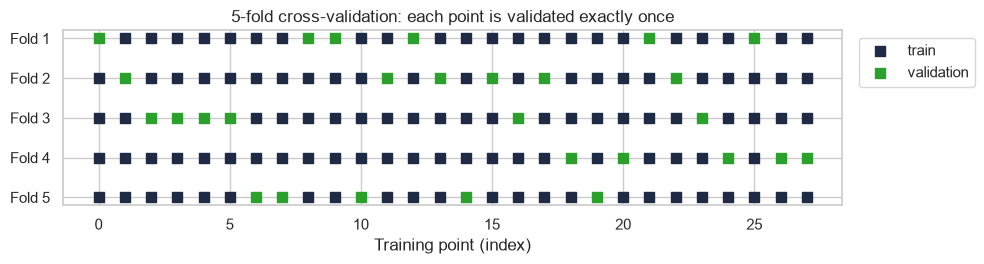

In [9]:
from sklearn.model_selection import KFold, cross_val_score

# what 5-fold cross-validation does with the 28 synthetic training points
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (tr_idx, val_idx) in enumerate(kf.split(wwr_train)):
    ax.scatter(tr_idx, [i] * len(tr_idx), marker="s", s=60, color="#1f2a44",
               label="train" if i == 0 else None)
    ax.scatter(val_idx, [i] * len(val_idx), marker="s", s=60, color="tab:green",
               label="validation" if i == 0 else None)
ax.set_yticks(range(5), [f"Fold {i + 1}" for i in range(5)])
ax.invert_yaxis()
ax.set_xlabel("Training point (index)")
ax.set_title("5-fold cross-validation: each point is validated exactly once")
ax.legend(loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

### Choosing the polynomial degree with cross-validation

We now choose the degree **without touching the test set**: for each degree we run 5-fold CV on the training points and look at the average validation error. Only at the end do we compare with the test error from 1.2, to see if CV picked well.

Degree chosen by 5-fold CV: 2


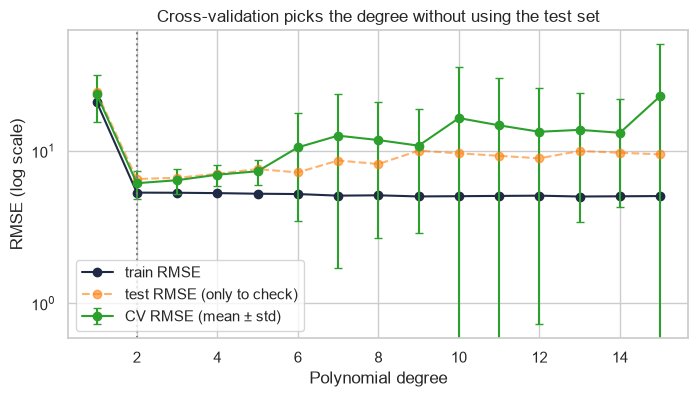

degree,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cv_mean,23.6,6.1,6.4,7.0,7.3,10.5,12.6,11.7,10.8,16.4,14.7,13.3,13.7,13.1,22.8
cv_std,8.0,1.3,1.2,1.1,1.3,7.1,10.9,9.1,7.9,18.9,15.4,12.6,10.3,8.9,27.1
train,21.0,5.3,5.3,5.3,5.2,5.2,5.1,5.1,5.0,5.0,5.1,5.1,5.0,5.0,5.0
test,24.3,6.5,6.6,7.1,7.6,7.2,8.6,8.2,10.0,9.6,9.3,8.9,10.0,9.7,9.5


In [10]:
cv_rows = []
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    # sklearn maximises scores, so errors are returned negative
    scores = -cross_val_score(model, wwr_train.reshape(-1, 1), dem_train,
                              cv=kf, scoring="neg_root_mean_squared_error")
    cv_rows.append({"degree": deg, "cv_mean": scores.mean(), "cv_std": scores.std()})
cv_poly = pd.DataFrame(cv_rows).merge(sweep, on="degree")

best_deg = int(cv_poly.loc[cv_poly["cv_mean"].idxmin(), "degree"])
print(f"Degree chosen by 5-fold CV: {best_deg}")

plt.figure(figsize=(8, 4))
plt.plot(cv_poly["degree"], cv_poly["train"], "o-", color="#1f2a44", label="train RMSE")
plt.errorbar(cv_poly["degree"], cv_poly["cv_mean"], yerr=cv_poly["cv_std"],
             fmt="o-", color="tab:green", capsize=3, label="CV RMSE (mean ± std)")
plt.plot(cv_poly["degree"], cv_poly["test"], "o--", color="tab:orange", alpha=0.6, label="test RMSE (only to check)")
plt.axvline(best_deg, color="grey", linestyle=":")
plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (log scale)")
plt.title("Cross-validation picks the degree without using the test set")
plt.legend()
plt.show()

cv_poly.round(1).set_index("degree").T

### Cross-validation on the housing data: folds must respect time

On the housing data a **shuffled** K-fold has the same problem as a random train/test split (1.1): the model validates on 1995 while having trained on 1994 *and* 1996 of the same country, which are almost identical. The score looks better than what we would get when forecasting.

So we use **time-based folds** (`TimeSeriesSplit`, an "expanding window"): split the training years 1977–2014 into consecutive blocks; each fold trains on all years **before** a block and validates on that block. Folds are cut on whole years, so all 26 countries of a year stay together.

In [11]:
from sklearn.model_selection import TimeSeriesSplit

train_years = df.loc[is_train, "year"].to_numpy()
unique_years = np.sort(np.unique(train_years))

# TimeSeriesSplit on the list of years, then map the years back to rows
time_folds = []
for tr_y, val_y in TimeSeriesSplit(n_splits=5).split(unique_years):
    tr_rows = np.where(np.isin(train_years, unique_years[tr_y]))[0]
    val_rows = np.where(np.isin(train_years, unique_years[val_y]))[0]
    time_folds.append((tr_rows, val_rows))
    print(f"train {unique_years[tr_y].min()}–{unique_years[tr_y].max()} ({len(tr_rows)} rows)"
          f"  →  validate {unique_years[val_y].min()}–{unique_years[val_y].max()} ({len(val_rows)} rows)")

train 1977–1984 (190 rows)  →  validate 1985–1990 (144 rows)
train 1977–1990 (334 rows)  →  validate 1991–1996 (148 rows)
train 1977–1996 (482 rows)  →  validate 1997–2002 (156 rows)
train 1977–2002 (638 rows)  →  validate 2003–2008 (156 rows)
train 1977–2008 (794 rows)  →  validate 2009–2014 (156 rows)


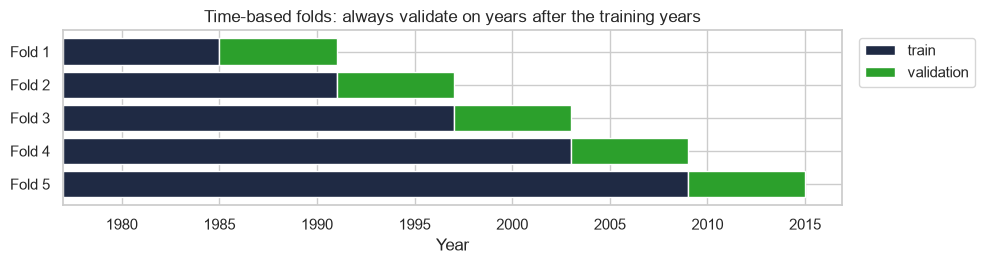

In [12]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (tr_rows, val_rows) in enumerate(time_folds):
    ax.barh(i, np.ptp(train_years[tr_rows]) + 1, left=train_years[tr_rows].min(), color="#1f2a44",
            label="train" if i == 0 else None)
    ax.barh(i, np.ptp(train_years[val_rows]) + 1, left=train_years[val_rows].min(), color="tab:green",
            label="validation" if i == 0 else None)
ax.set_yticks(range(5), [f"Fold {i + 1}" for i in range(5)])
ax.invert_yaxis()
ax.set_xlabel("Year")
ax.set_title("Time-based folds: always validate on years after the training years")
ax.legend(loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

### Choosing the tree depth with cross-validation

We repeat the decision-tree experiment from 1.2, but now choose `max_depth` from the **cross-validation** score instead of peeking at the test set. For comparison we also run a **shuffled** 5-fold CV, to see how much it flatters the model.

max_depth chosen by time-based CV: 5


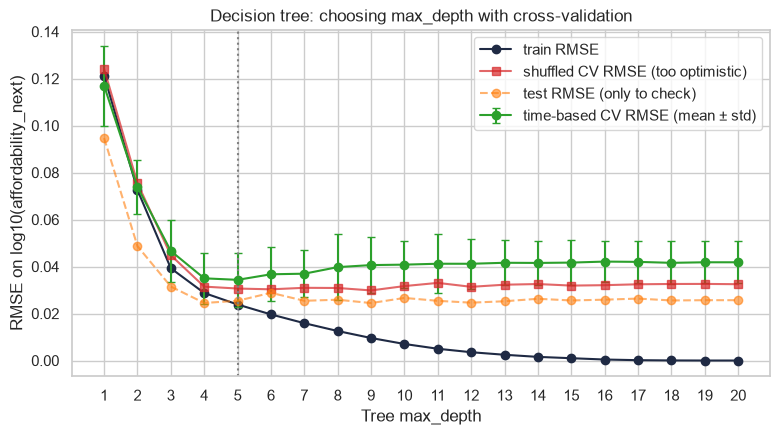

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
time_cv_mean,0.1170,0.0738,0.0466,0.0350,0.0343,0.0367,0.0370,0.0398,0.0406,0.0408,0.0412,0.0412,0.0416,0.0415,0.0417,0.0421,0.0420,0.0416,0.0418,0.0418
time_cv_std,0.0171,0.0115,0.0130,0.0109,0.0114,0.0115,0.0100,0.0140,0.0118,0.0100,0.0126,0.0106,0.0096,0.0093,0.0094,0.0089,0.0091,0.0092,0.0090,0.0090
shuffled_cv_mean,0.1241,0.0755,0.0448,0.0315,0.0306,0.0303,0.0310,0.0309,0.0298,0.0317,0.0330,0.0314,0.0323,0.0326,0.0319,0.0321,0.0325,0.0326,0.0326,0.0325
train,0.1213,0.0726,0.0393,0.0287,0.0238,0.0196,0.0159,0.0126,0.0096,0.0070,0.0050,0.0035,0.0024,0.0015,0.0010,0.0004,0.0001,0.0000,0.0000,0.0000
test,0.0947,0.0487,0.0315,0.0245,0.0254,0.0288,0.0254,0.0259,0.0245,0.0266,0.0254,0.0246,0.0252,0.0263,0.0256,0.0259,0.0264,0.0256,0.0257,0.0257


In [13]:
shuffled_kf = KFold(n_splits=5, shuffle=True, random_state=42)

depth_rows = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    time_scores = -cross_val_score(tree, X_train, y_train, cv=time_folds,
                                   scoring="neg_root_mean_squared_error")
    shuffled_scores = -cross_val_score(tree, X_train, y_train, cv=shuffled_kf,
                                       scoring="neg_root_mean_squared_error")
    depth_rows.append({"max_depth": depth,
                       "time_cv_mean": time_scores.mean(), "time_cv_std": time_scores.std(),
                       "shuffled_cv_mean": shuffled_scores.mean()})
cv_tree = pd.DataFrame(depth_rows).merge(tree_sweep, on="max_depth")

best_depth = int(cv_tree.loc[cv_tree["time_cv_mean"].idxmin(), "max_depth"])
print(f"max_depth chosen by time-based CV: {best_depth}")

plt.figure(figsize=(9, 4.5))
plt.plot(cv_tree["max_depth"], cv_tree["train"], "o-", color="#1f2a44", label="train RMSE")
plt.errorbar(cv_tree["max_depth"], cv_tree["time_cv_mean"], yerr=cv_tree["time_cv_std"],
             fmt="o-", color="tab:green", capsize=3, label="time-based CV RMSE (mean ± std)")
plt.plot(cv_tree["max_depth"], cv_tree["shuffled_cv_mean"], "s-", color="tab:red", alpha=0.7,
         label="shuffled CV RMSE (too optimistic)")
plt.plot(cv_tree["max_depth"], cv_tree["test"], "o--", color="tab:orange", alpha=0.6, label="test RMSE (only to check)")
plt.axvline(best_depth, color="grey", linestyle=":")
plt.xticks(range(1, 21))
plt.xlabel("Tree max_depth")
plt.ylabel("RMSE on log10(affordability_next)")
plt.title("Decision tree: choosing max_depth with cross-validation")
plt.legend()
plt.show()

cv_tree.round(4).set_index("max_depth").T

### Final check on the test set (once)

With the depth chosen by cross-validation, we train on the **full** training set (1977–2014) and evaluate **once** on the test set (2015–2024).

In [14]:
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train, y_train)
test_rmse = root_mean_squared_error(y_test, final_tree.predict(X_test))
cv_at_best = cv_tree.loc[cv_tree["max_depth"] == best_depth].iloc[0]

print(f"max_depth = {best_depth}")
print(f"time-based CV RMSE: {cv_at_best['time_cv_mean']:.4f} ± {cv_at_best['time_cv_std']:.4f}")
print(f"shuffled CV RMSE:   {cv_at_best['shuffled_cv_mean']:.4f}")
print(f"test RMSE:          {test_rmse:.4f}  (≈ {(10 ** test_rmse - 1):.1%} typical error on affordability)")

max_depth = 5
time-based CV RMSE: 0.0343 ± 0.0114
shuffled CV RMSE:   0.0306
test RMSE:          0.0254  (≈ 6.0% typical error on affordability)


### What we see

**Synthetic example**
- 5-fold CV picks **degree 2**, the true shape of the curve, without ever looking at the test set. Its CV error (≈ 6.1) is close to the test error (≈ 6.5).
- For high degrees the CV error is not only higher but also much more **spread out** across folds (large error bars): an overfitted model is unstable and depends heavily on which points it happened to see.

**Housing data**
- Time-based CV picks **max_depth = 5** (CV RMSE ≈ 0.034 ± 0.011), close to the best depth we saw on the test set in 1.2, but this time chosen honestly.
- **Shuffled CV is too optimistic:** from depth 4 onwards it reports lower errors than time-based CV (e.g. 0.030 vs 0.042 at depth 9) and its minimum sits at a deeper tree. The model is rewarded for "seeing" neighbouring years, which it cannot do when forecasting.
- **Final test RMSE ≈ 0.025** (≈ 6% typical error). It is even lower than the CV estimate. This is not a mistake: the CV folds include volatile periods (1980s–90s, the 2008 crisis), while 2015–2024 was calmer. The CV score is the more cautious estimate to report.

**Takeaway:** use cross-validation on the training set to compare models and choose hyperparameters; touch the test set **once**, at the end. On time-ordered data, the folds must respect time too.

### Why not a single validation split?

With one split, the score depends on *which* rows happened to land in the validation part (lucky or unlucky). Averaging over 5 splits is more **stable**, and the **standard deviation** of the 5 scores tells us how much the score could change by chance.

Below: the same degree-2 model scored with 50 different single 80/20 splits of the synthetic training points, compared with 50 runs of 5-fold CV (each with a different shuffle).

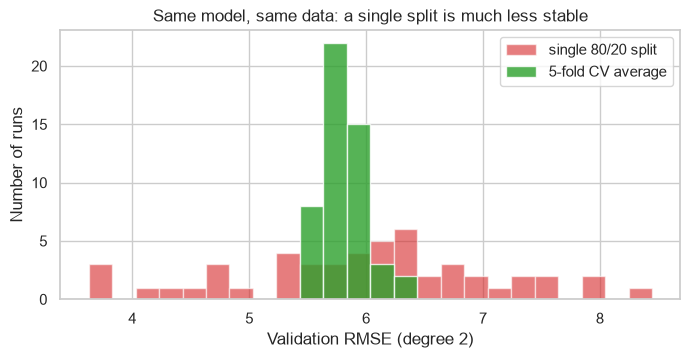

single split: 3.6 to 8.4 (std 1.09)
5-fold CV:    5.5 to 6.4 (std 0.19)


In [15]:
from sklearn.model_selection import ShuffleSplit

model = make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression())
X_wwr = wwr_train.reshape(-1, 1)

single_split, five_fold = [], []
for seed in range(50):
    single = ShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    single_split.append(-cross_val_score(model, X_wwr, dem_train, cv=single,
                                         scoring="neg_root_mean_squared_error")[0])
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    five_fold.append(-cross_val_score(model, X_wwr, dem_train, cv=folds,
                                      scoring="neg_root_mean_squared_error").mean())

bins = np.linspace(min(single_split), max(single_split), 25)
plt.figure(figsize=(8, 3.5))
plt.hist(single_split, bins=bins, alpha=0.6, color="tab:red", label="single 80/20 split")
plt.hist(five_fold, bins=bins, alpha=0.8, color="tab:green", label="5-fold CV average")
plt.xlabel("Validation RMSE (degree 2)")
plt.ylabel("Number of runs")
plt.title("Same model, same data: a single split is much less stable")
plt.legend()
plt.show()

print(f"single split: {np.min(single_split):.1f} to {np.max(single_split):.1f} (std {np.std(single_split):.2f})")
print(f"5-fold CV:    {np.min(five_fold):.1f} to {np.max(five_fold):.1f} (std {np.std(five_fold):.2f})")

## 1.4 Baselines

Before celebrating a score, ask: *what score would a "dumb" model get?* A **baseline** is the simplest possible prediction:
- **Regression:** always predict the **mean** of the training targets.
- **Classification:** always predict the **most frequent class**.

scikit-learn has these as `DummyRegressor` and `DummyClassifier`. If your model cannot clearly beat the baseline, it has not learned anything useful.

For our forecasting task there is a second, much stronger baseline: **"next year = this year"** (persistence). On Day 1 we saw that this year's affordability correlates ≈ 0.99 with next year's (README §8.3), so this simple rule will already score very well. It is the real bar our models must clear.

`cross_validate` runs cross-validation for us: it gives back the score of each of the 5 folds. We use the same time-based folds as in 1.3.

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import cross_validate

class PersistenceRegressor(RegressorMixin, BaseEstimator):
    """Baseline: next year's affordability = this year's affordability."""
    def fit(self, X, y):
        return self  # nothing to learn

    def predict(self, X):
        return np.log10(X["affordability"].to_numpy())

models = {
    "Baseline: mean": DummyRegressor(strategy="mean"),
    "Baseline: next year = this year": PersistenceRegressor(),
    f"Decision tree (max_depth={best_depth})": DecisionTreeRegressor(max_depth=best_depth, random_state=42),
}

fold_scores = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=time_folds,
                         scoring="neg_root_mean_squared_error")
    fold_scores[name] = -res["test_score"]

fold_table = pd.DataFrame(fold_scores, index=[f"Fold {i + 1}" for i in range(5)]).T
fold_table["mean"] = fold_table.mean(axis=1)
fold_table["std"] = fold_table.iloc[:, :5].std(axis=1, ddof=0)
fold_table.round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,mean,std
Baseline: mean,0.2171,0.1789,0.1291,0.1186,0.0919,0.1471,0.0449
Baseline: next year = this year,0.0341,0.0254,0.0259,0.0278,0.0194,0.0265,0.0047
Decision tree (max_depth=5),0.0566,0.0323,0.0295,0.0272,0.0260,0.0343,0.0114


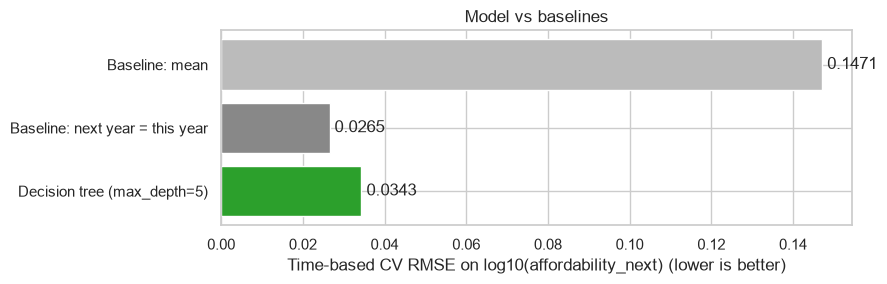

,CV RMSE,test RMSE,typical error
model,,,
Baseline: mean,0.1471,0.0652,≈ 16.2%
Baseline: next year = this year,0.0265,0.0222,≈ 5.3%
Decision tree (max_depth=5),0.0343,0.0254,≈ 6.0%


In [17]:
# final check on the test set, once, for the baselines and the tree
test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rmse = root_mean_squared_error(y_test, model.predict(X_test))
    test_rows.append({"model": name, "CV RMSE": fold_table.loc[name, "mean"], "test RMSE": rmse,
                      "typical error": f"≈ {10 ** rmse - 1:.1%}"})
results = pd.DataFrame(test_rows).set_index("model")

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(results.index, results["CV RMSE"], color=["#bbbbbb", "#888888", "tab:green"])
for i, v in enumerate(results["CV RMSE"]):
    ax.text(v, i, f" {v:.4f}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Time-based CV RMSE on log10(affordability_next) (lower is better)")
ax.set_title("Model vs baselines")
plt.tight_layout()
plt.show()

results.round(4)

### What we see

**Single split vs cross-validation:** the same degree-2 model gets anything from ≈ 3.6 to 8.4 with a single 80/20 split, depending only on which points land in validation. The 5-fold average stays between ≈ 5.5 and 6.4, about **5× more stable** (std 0.19 vs 1.09).

**Baselines on the housing data**
- **Mean baseline:** CV RMSE ≈ 0.147 (≈ 16% typical error on the test set). The decision tree beats it easily, so it has learned *something*.
- **"Next year = this year":** CV RMSE ≈ **0.027**, better than the tree's ≈ 0.034, in every fold except fold 4 where the two are nearly tied. On the test set the same: 0.022 vs 0.025 (≈ 5.3% vs 6.0%).
- So the decision tree does **not** beat the honest baseline. Beating the mean baseline alone would have made it look good; the persistence baseline shows it adds no value yet.

**Why the tree struggles:** a tree can only predict values it has seen in its leaves (averages of groups of training rows). Affordability drifts to new levels over time, so a tree predicting the *level* loses precision that simply copying this year's value keeps.

**For the next sections:** every model we try must be compared against **"next year = this year"**, not just the mean. A promising idea is to predict the **change** from this year to next year instead of the level, so that the model only has to learn the part persistence cannot.

### R² of the baselines

The mean baseline has an **R² of 0** by definition (see section 4.2): R² measures how much better a model is than always predicting the mean. Every real model must do clearly better than this.

One subtlety on our data: the baseline predicts the mean of the **training** years, but is scored on **later** years whose mean is different (affordability drifts over time). So its R² comes out **below 0**, which means "worse than knowing the mean of the period being predicted": about −0.1 in cross-validation, and almost −1 on the test set, because 2015–2024 is a calm period with little spread, so even a modest miss of the level is large compared with it.

In [18]:
r2_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=time_folds, scoring="r2")
    model.fit(X_train, y_train)
    r2_rows.append({"model": name, "CV R²": res["test_score"].mean(),
                    "test R²": model.score(X_test, y_test)})
pd.DataFrame(r2_rows).set_index("model").round(3)

,CV R²,test R²
model,,
Baseline: mean,-0.100,-0.974
Baseline: next year = this year,0.958,0.770
Decision tree (max_depth=5),0.937,0.699


## 1.5 Data leakage

**Data leakage** happens when information that would **not be available at prediction time** sneaks into the training data. The model then looks brilliant in the notebook and fails in the real world.

On Day 1 we removed two leaking features (`affordability_vs_own_avg`, `affordability_position`) because they use each country's average, minimum and maximum over **all** years, including the future. Here we show a more blatant case, the kind that is easy to create by accident during feature engineering: **next year's growth in affordability**.

It is computed from the target: `growth_next = affordability_next / affordability`. So

`log10(affordability_next) = log10(affordability) + log10(growth_next)`

If we give the model this growth, it does not need to learn anything. Let's see what happens with a linear regression:

In [19]:
# honest inputs: our features plus this year's affordability on the same log scale as the target
X_honest = X.assign(log_affordability=np.log10(df["affordability"]))
# leaky inputs: the same, plus next year's growth (computed from the target!)
X_leaky = X_honest.assign(log_growth_next=np.log10(df["affordability_next"] / df["affordability"]))

leak_rows = []
for label, X_variant in {"honest features": X_honest, "+ next year's growth (leak)": X_leaky}.items():
    Xv_train, Xv_test = X_variant[is_train], X_variant[~is_train]
    res = cross_validate(LinearRegression(), Xv_train, y_train, cv=time_folds,
                         scoring=["neg_root_mean_squared_error", "r2"])
    lr = LinearRegression().fit(Xv_train, y_train)
    leak_rows.append({"inputs": label,
                      "CV RMSE": -res["test_neg_root_mean_squared_error"].mean(),
                      "CV R²": res["test_r2"].mean(),
                      "test RMSE": root_mean_squared_error(y_test, lr.predict(Xv_test)),
                      "test R²": lr.score(Xv_test, y_test)})
pd.DataFrame(leak_rows).set_index("inputs").round(4)

,CV RMSE,CV R²,test RMSE,test R²
inputs,,,,
honest features,0.0222,0.9718,0.0192,0.8279
+ next year's growth (leak),0.0000,1.0000,0.0000,1.0000


A **perfect score is a red flag**, not a reason to celebrate. In real life, when we forecast affordability for 2026 at the end of 2025, we do not know the growth from 2025 to 2026, because that is computed **from the answer** we are trying to predict!

Note that leakage does not always show up as a better score. Adding back the two Day 1 features barely changes the decision tree's score, but they are still invalid: a model using them would rely on information (a country's future minimum, maximum and average) that it can never have when forecasting. **Leakage is about what is available at prediction time, not about the score.**

⚠️ **Watch out – the subtle kind of leakage:** leakage also happens when we fit preprocessing steps (imputers, scalers, encoders) on the **whole** dataset before splitting: the training data then "knows" something about the test data (e.g. its mean). The fix is to fit every preprocessing step **on the training data only**. Doing this by hand is error-prone… which is exactly why scikit-learn has **pipelines**.

Below, a K-nearest-neighbours model (which needs scaled inputs) is cross-validated twice:
- **Wrong:** `StandardScaler` fitted on **all** rows (including the test years) before cross-validation.
- **Right:** scaler and model in a **pipeline**, so in each fold the scaler is fitted only on that fold's training rows.

In [20]:
from sklearn.neighbors import KNeighborsRegressor

# WRONG: scale using statistics of the whole dataset, then cross-validate
X_scaled_all = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
wrong = -cross_val_score(KNeighborsRegressor(n_neighbors=5), X_scaled_all[is_train], y_train,
                         cv=time_folds, scoring="neg_root_mean_squared_error")

# RIGHT: the pipeline refits the scaler inside every fold, on training rows only
knn_pipeline = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
right = -cross_val_score(knn_pipeline, X_train, y_train,
                         cv=time_folds, scoring="neg_root_mean_squared_error")

pd.DataFrame({"scaler fitted on all data (leak)": wrong, "pipeline (correct)": right},
             index=[f"Fold {i + 1}" for i in range(5)]).T.assign(mean=lambda t: t.mean(axis=1)).round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,mean
scaler fitted on all data (leak),0.0777,0.0529,0.0692,0.0726,0.0541,0.0653
pipeline (correct),0.0943,0.0782,0.0828,0.0835,0.0677,0.0813


### What we see

- **R²:** the mean baseline scores ≈ −0.1 (CV) and ≈ −0.97 (test); "next year = this year" already reaches ≈ 0.96 (CV) and ≈ 0.77 (test). A high R² on its own means little for this task, because persistence gets most of it for free.
- **Target leakage:** adding next year's growth gives a **perfect** score: RMSE = 0 and R² = 1, in every fold and on the test set. The model simply adds the two logs together. This is the clearest possible red flag.
- **Preprocessing leakage:** fitting the scaler on all data makes KNN look ≈ **20% better** than it really is (CV RMSE 0.065 vs 0.081), and better in every fold. The scaler "knew" the range of the test years (e.g. that `year` goes up to 2024). The pipeline gives the honest number.
- **Side note:** the *honest* linear regression, which only gets this year's affordability on the log scale, reaches CV RMSE ≈ 0.022 and test RMSE ≈ 0.019. That is the first model in this notebook to **beat "next year = this year"** (0.027 and 0.022). We come back to it in the next sections.

**Takeaway:** for every input, ask *"would I know this value at the moment I make the prediction?"*, and put all preprocessing inside a pipeline so it is refitted on training data only.

# 2. scikit-learn pipelines and encoders

## 2.1 The scikit-learn API: fit, transform, predict

We have already used several scikit-learn objects in this notebook (`StandardScaler`, `LinearRegression`, `DecisionTreeRegressor`, `DummyRegressor`). Every object in scikit-learn follows the same small set of methods, which makes them easy to combine:

| Type of object | Examples | Methods | What it does |
|---|---|---|---|
| **Transformer** | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` | `fit()` + `transform()` (or `fit_transform()`) | **Learns** something from the data (a median, a mean, a list of categories) and then **changes** the data |
| **Estimator / model** | `LinearRegression`, `RandomForestClassifier` | `fit()` + `predict()` | **Learns** the relation between `X` and `y` and **predicts** `y` for new `X` |

The golden rule: **`fit` only on training data**, then `transform` / `predict` on anything.

Even our own `PersistenceRegressor` from 1.4 follows this API (a `fit` that learns nothing and a `predict`), which is why `cross_validate` could use it like any other model.

## 2.2 The problem pipelines solve

Let's train a small model on three numeric columns with very different scales:
- `year`: values around **2000**
- `affordability`: values from about **40 to 600**
- `real_hpi_change_pct`: yearly change in real house prices, roughly **−25 to +30**

A K-nearest-neighbours model compares rows by distance, so without rescaling, the column with the biggest numbers dominates. We use a **scaler**: `StandardScaler` rescales each column to mean 0 and standard deviation 1.

Our model-ready file has **no missing values** (Day 1 removed the rows without lags or target). But in real use, the newest year's statistics often arrive late or incomplete, so a model should be able to handle gaps. To practise, we **simulate** this by blanking out 5% of the values in each column at random, and add an **imputer** (`SimpleImputer`, filling gaps with the column median).

**Version 1: by hand.**

In [21]:
from sklearn.impute import SimpleImputer

cols = ["year", "affordability", "real_hpi_change_pct"]

# simulated gaps: blank out 5% of each column at random (a copy, the real data is untouched)
gap_rng = np.random.default_rng(0)
X_small = df[cols].copy()
for col in cols:
    X_small.loc[gap_rng.random(len(X_small)) < 0.05, col] = np.nan

X_small_train, X_small_test = X_small[is_train], X_small[~is_train]
print("Missing values in train:", X_small_train.isna().sum().to_dict())
print("Missing values in test: ", X_small_test.isna().sum().to_dict())
X_small_train.describe().round(1)

Missing values in train: {'year': 43, 'affordability': 55, 'real_hpi_change_pct': 47}
Missing values in test:  {'year': 13, 'affordability': 22, 'real_hpi_change_pct': 10}


,year,affordability,real_hpi_change_pct
count,907.0,895.0,903.0
mean,1995.9,101.5,1.6
std,10.9,62.1,7.1
min,1977.0,37.3,-25.3
25%,1986.0,71.4,-2.7
50%,1996.0,89.3,1.1
75%,2005.0,112.4,5.7
max,2014.0,622.8,30.6


In [22]:
# Step 1: imputer, learns the median of each column on the TRAINING data only
imputer = SimpleImputer(strategy="median")
X_tr = imputer.fit_transform(X_small_train)
X_te = imputer.transform(X_small_test)          # transform only, never fit on test

# Step 2: scaler, learns mean and std of each column on the TRAINING data only
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_te = scaler.transform(X_te)

# Step 3: model
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_tr, y_train)
y_pred = knn.predict(X_te)

print("Medians learned by the imputer:", {c: round(float(v), 1) for c, v in zip(cols, imputer.statistics_)})
print("Means learned by the scaler:   ", {c: round(float(v), 1) for c, v in zip(cols, scaler.mean_)})
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred):.4f}")

Medians learned by the imputer: {'year': 1996.0, 'affordability': 89.3, 'real_hpi_change_pct': 1.1}
Means learned by the scaler:    {'year': 1995.9, 'affordability': 100.8, 'real_hpi_change_pct': 1.6}
Test RMSE: 0.0395


This works, but look at how much can go wrong:
- **Six steps** that must run in exactly the right order, with the right `fit_transform` / `transform` on each side.
- One slip, such as `imputer.fit_transform(X_small_test)` or scaling before splitting, is **silent leakage** (1.5): no error, just a score that is too good.
- To make a prediction for a new year, we must remember to repeat **every** step with the **same** fitted imputer and scaler.
- It does not work with `cross_val_score`: in each fold the imputer and scaler would have to be refitted on that fold's training rows, which means writing the loop ourselves.

We evaluated on the test set here only to show the mechanics. A pipeline solves all four problems.

It works, but every step must be repeated in the right order, with `fit_transform` in one place and `transform` in the other. Forget one, or use `fit_transform` on the test data by mistake, and you get wrong results or leakage. Now imagine doing this inside 5-fold cross-validation…

**Version 2: with a `Pipeline`.** A pipeline chains the steps into **one object** that behaves like a model: one `fit`, one `predict`.

In [23]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=10)),
])

pipe.fit(X_small_train, y_train)          # fits imputer, scaler and model, all on training data
y_pred_pipe = pipe.predict(X_small_test)  # only transforms the test data, then predicts

print(f"Test RMSE (pipeline): {root_mean_squared_error(y_test, y_pred_pipe):.4f}")
print("Same predictions as the by-hand version:", np.allclose(y_pred, y_pred_pipe))
pipe

Test RMSE (pipeline): 0.0395
Same predictions as the by-hand version: True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['year','affordability','real_hpi_change_pct']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, 

Same result, but now the whole recipe is **one object**. It can go straight into cross-validation, and in every fold the imputer and scaler are refitted on that fold's training rows only, with no extra code:

In [24]:
pipe_scores = -cross_val_score(pipe, X_small_train, y_train, cv=time_folds,
                               scoring="neg_root_mean_squared_error")
print("RMSE per fold:", pipe_scores.round(4))
print(f"CV RMSE: {pipe_scores.mean():.4f} ± {pipe_scores.std():.4f}")

RMSE per fold: [0.1324 0.1066 0.0795 0.0827 0.045 ]
CV RMSE: 0.0892 ± 0.0292


(We just peeked at the test set to show that both versions are identical. From now on, the test set stays locked until section 4.7.)

## 2.3 Encoding categorical variables

Models only understand **numbers**. Columns that contain text must be **encoded**. First we need to know what *kind* of category we have:

| Kind | Meaning | Examples in our data |
|---|---|---|
| **Nominal** | Categories with **no natural order** | `region` (Nordic is not "more" than Oceania), `country` / `iso` |
| **Ordinal** | Categories with a **meaningful order** | `decade`: 1970s < 1980s < … < 2020s |

In the model-ready file, Day 1 already one-hot encoded `region` into ten 0/1 columns (`region_Africa`, `region_Asia`, …). To see how the encoders work, we rebuild the original text column from them, and write `decade` as text labels.

Let's look at the main encoders on 5 example rows:

In [25]:
region_cols = [c for c in df.columns if c.startswith("region_")]

cat_df = pd.DataFrame({
    "country": df["iso"],
    "region": df[region_cols].idxmax(axis=1).str.removeprefix("region_"),
    "decade": df["decade"].astype(str) + "s",
})

# 5 rows with different regions and decades
picks = [("AUS", 1979), ("KOR", 1988), ("FIN", 1995), ("USA", 2007), ("ESP", 2021)]
rows = [df.index[(df["iso"] == iso) & (df["year"] == year)][0] for iso, year in picks]
examples = cat_df.loc[rows].reset_index(drop=True)
examples

,country,region,decade
0,AUS,Oceania,1970s
1,KOR,Asia,1980s
2,FIN,Nordic,1990s
3,USA,North America,2000s
4,ESP,Southern Europe,2020s


In [26]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Nominal -> OneHotEncoder: one 0/1 column per category, no order implied
onehot = OneHotEncoder(sparse_output=False)
region_onehot = pd.DataFrame(onehot.fit_transform(examples[["region"]]),
                             columns=onehot.get_feature_names_out(), dtype=int)

# Ordinal -> OrdinalEncoder with the order spelled out: 1970s=0, 1980s=1, ...
decade_order = ["1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]
ordinal = OrdinalEncoder(categories=[decade_order])
decade_ordinal = pd.DataFrame(ordinal.fit_transform(examples[["decade"]]),
                              columns=["decade_ordinal"], dtype=int)

pd.concat([examples, region_onehot, decade_ordinal], axis=1)

,country,region,decade,region_Asia,region_Nordic,region_North America,region_Oceania,region_Southern Europe,decade_ordinal
0,AUS,Oceania,1970s,0,0,0,1,0,0
1,KOR,Asia,1980s,1,0,0,0,0,1
2,FIN,Nordic,1990s,0,1,0,0,0,2
3,USA,North America,2000s,0,0,1,0,0,3
4,ESP,Southern Europe,2020s,0,0,0,0,1,5


### One-hot encoding: `OneHotEncoder`

Creates **one 0/1 column per category**. A row from Finland gets a 1 in the `region_Nordic` column and 0 everywhere else. No order is invented: each category is simply "present" or "absent". This is the **default choice for nominal categories**.

⚠️ **Watch out:** one-hot encoding creates **many columns** when there are many categories: `region` has 10 categories → 10 columns, `country` has 26 → 26 columns. That is fine, but it would not be for 10,000 categories (e.g. if we had city- or neighbourhood-level data). Also, a category that appears in new data but never in training would **crash** the encoder; `handle_unknown="ignore"` turns it into all zeros instead.

Below, the encoder learns the 26 countries from the training data, and then meets **Mexico**, which is not in our dataset:

In [27]:
country_train = cat_df.loc[is_train, ["country"]]
new_rows = pd.DataFrame({"country": ["ESP", "MEX"]})   # MEX never seen in training

strict = OneHotEncoder(sparse_output=False).fit(country_train)
try:
    strict.transform(new_rows)
except ValueError as e:
    print("Default encoder:", str(e).split("\n")[0])

tolerant = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(country_train)
encoded = pd.DataFrame(tolerant.transform(new_rows), columns=tolerant.get_feature_names_out(),
                       index=new_rows["country"], dtype=int)
print(f"\nWith handle_unknown='ignore': {encoded.shape[1]} columns; MEX row sums to {encoded.loc['MEX'].sum()}")
encoded[["country_DEU", "country_ESP", "country_FRA", "country_USA"]]

Default encoder: Found unknown categories ['MEX'] in column 0 during transform

With handle_unknown='ignore': 26 columns; MEX row sums to 0


,country_DEU,country_ESP,country_FRA,country_USA
country,,,,
ESP,0,1,0,0
MEX,0,0,0,0


### Ordinal encoding: `OrdinalEncoder`

Replaces each category with an **integer**. It is the right choice when the order is real, and we must **tell the encoder the order**: otherwise it uses **alphabetical** order!

`decade` happens to sort correctly in alphabetical order ("1970s" < "1980s" < …), so it cannot show the problem. We use an **illustrative affordability band** built from this year's affordability (cut-offs chosen only for this example):

| Band | Affordability |
|---|---|
| Affordable | below 80 |
| Moderate | 80–100 |
| Unaffordable | 100–130 |
| Severely unaffordable | 130 and above |

Alphabetically, "Severely unaffordable" would come **before** "Unaffordable", which is wrong.

We also add a row whose value is **`Unknown`** (as if Italy's latest statistics had not been published yet, like the simulated gaps in 2.2). `Unknown` is not in the list, so we place it at **-1**: outside the 0–3 scale, so the model can tell it apart from a real band. Unlike a real price listing, we have no evidence that missing values mean "cheap" here, so -1 is only a marker, not a claim about affordability.

In [28]:
bands = ["Affordable", "Moderate", "Unaffordable", "Severely unaffordable"]
affordability_band = pd.cut(df["affordability"], bins=[0, 80, 100, 130, np.inf], labels=bands, right=False)

band_examples = examples[["country", "decade"]].copy()
band_examples["affordability"] = df.loc[rows, "affordability"].round(1).to_numpy()
band_examples["band"] = affordability_band.loc[rows].astype(str).to_numpy()
band_examples.loc[len(band_examples)] = ["ITA", "2020s", np.nan, "Unknown"]   # value not published yet

# WRONG: no order given -> alphabetical
alphabetical = OrdinalEncoder().fit(band_examples[["band"]])
band_examples["band_alphabetical"] = alphabetical.transform(band_examples[["band"]]).astype(int)

# RIGHT: order spelled out, Unknown -> -1
ordered = OrdinalEncoder(categories=[bands], handle_unknown="use_encoded_value", unknown_value=-1)
ordered.fit(band_examples.loc[band_examples["band"] != "Unknown", ["band"]])
band_examples["band_ordinal"] = ordered.transform(band_examples[["band"]]).astype(int)

print("Alphabetical order:", list(alphabetical.categories_[0]))
print("Our order:         ", list(ordered.categories_[0]))
band_examples

Alphabetical order: ['Affordable', 'Moderate', 'Severely unaffordable', 'Unaffordable', 'Unknown']
Our order:          ['Affordable', 'Moderate', 'Unaffordable', 'Severely unaffordable']


,country,decade,affordability,band,band_alphabetical,band_ordinal
0,AUS,1970s,38.9,Affordable,0,0
1,KOR,1980s,371.7,Severely unaffordable,2,3
2,FIN,1990s,92.4,Moderate,1,1
3,USA,2000s,101.1,Unaffordable,3,2
4,ESP,2020s,102.0,Unaffordable,3,2
5,ITA,2020s,NaN,Unknown,4,-1


**What we see**
- **One-hot:** the default encoder **crashes** on Mexico; with `handle_unknown="ignore"` Mexico simply gets 0 in all 26 country columns, while Spain gets a 1 in `country_ESP`.
- **Ordinal, alphabetical (wrong):** Korea 1988 ("Severely unaffordable") gets **2**, *lower* than the USA 2007 ("Unaffordable", **3**), and `Unknown` gets **4**, as if a missing value were the least affordable of all. A model would learn from this invented order.
- **Ordinal, with our order (right):** Affordable 0 < Moderate 1 < Unaffordable 2 < Severely unaffordable 3, and `Unknown` sits apart at **-1**.

### "Label encoding": `LabelEncoder`

When people say "label encoding" they usually mean: give each category an integer, in alphabetical order. scikit-learn's `LabelEncoder` does exactly that, but note its name: it is designed for **labels**, i.e. the **target `y`** of a classification problem (we use it in Part B), **not for features**.

Let's see what it does to `region`:

In [29]:
from sklearn.preprocessing import LabelEncoder

label_enc = LabelEncoder()
region_codes = label_enc.fit_transform(cat_df["region"])

pd.DataFrame({"region": label_enc.classes_,
              "code": label_enc.transform(label_enc.classes_)}).set_index("region").T

region,Africa,Asia,Central/Eastern Europe,Latin America,Middle East,Nordic,North America,Oceania,Southern Europe,Western Europe
code,0,1,2,3,4,5,6,7,8,9


The codes are alphabetical. A linear model would now believe that **Western Europe (9) is "nine times more" than Asia (1)**, and that the Middle East (4) lies "between" Latin America (3) and the Nordic countries (5). These relations are **invented**: the encoding creates a fake order. For a nominal feature, this can badly mislead some models (we measure the damage in section 4.3).

### Target encoding: `TargetEncoder`

A cleverer option for nominal columns with **many** categories: replace each category with the **average target** of that category (here: each country with its average `log10(affordability_next)`). One column instead of 26, and the numbers are meaningful.

⚠️ **Watch out:** it uses the target, so it can leak. scikit-learn's `TargetEncoder` protects against this with an internal cross-validation when you call `fit_transform`: each row is encoded with averages computed **without** the rows in its own fold, so a row never sees its own target.

We fit it on the **training** years only:

In [30]:
from sklearn.preprocessing import TargetEncoder

country_train = cat_df.loc[is_train, ["country"]]

# internal 5-fold cross-fitting (shuffled), used only by fit_transform
target_enc = TargetEncoder(target_type="continuous", cv=KFold(n_splits=5, shuffle=True, random_state=42))
country_encoded = target_enc.fit_transform(country_train, y_train)   # cross-fitted: safe for training rows

te_table = pd.DataFrame({
    "plain average (leaks)": y_train.groupby(country_train["country"]).mean(),
    "encoding for new data": pd.Series(target_enc.encodings_[0], index=target_enc.categories_[0]),
    "fit_transform: min": pd.Series(country_encoded[:, 0], index=country_train.index).groupby(country_train["country"]).min(),
    "fit_transform: max": pd.Series(country_encoded[:, 0], index=country_train.index).groupby(country_train["country"]).max(),
})
te_table.sort_values("plain average (leaks)").round(3)

,plain average (leaks),encoding for new data,fit_transform: min,fit_transform: max
LUX,1.732,1.734,1.723,1.748
AUS,1.755,1.756,1.746,1.769
NZL,1.760,1.762,1.746,1.793
CAN,1.784,1.785,1.778,1.795
NLD,1.852,1.853,1.844,1.860
GBR,1.861,1.862,1.849,1.876
BEL,1.876,1.877,1.860,1.886
IRL,1.891,1.892,1.888,1.900
SWE,1.893,1.893,1.881,1.908
ISR,1.905,1.905,1.898,1.910


**What we see**
- **One column instead of 26.** Each country gets one number: from ≈ 1.73 (Luxembourg) to ≈ 2.36 (South Korea).
- **But read these numbers carefully.** Luxembourg, Australia, New Zealand and Canada get the *lowest* values, although on Day 1 they were the *least* affordable since 2000. The reason is in the README limitations: our columns are **indexes, not money**. Each country's index is relative to its own base year, so the level mostly tells us how far a country has moved from its base, not how affordable it is compared with other countries. Target encoding faithfully learns this artefact. Always check that the encoded numbers make sense.
- The **plain average** uses every training row's own target, so a model trained on it would partly be fed the answer.
- **`fit_transform`** gives each row a value from the *other* folds, so rows of the same country get slightly different values (min ≠ max). The column "encoding for new data" is what `transform` will use later on validation and test rows. The values are also **shrunk** a little towards the overall average (smoothing), which protects small categories: Korea, the most extreme, is shrunk the most (2.361 → 2.339).
- The internal cross-validation shuffles rows, so on our data a row can still be encoded using neighbouring years of the same country. With only 26 countries, one-hot encoding is simpler and safer; target encoding pays off with hundreds or thousands of categories.